# 大模型微调 01：大模型背景简介与主要架构

本篇对应课程第一章，资料来自 `01-笔记/Day01 笔记.md`、`01-课件/第一章：大模型背景简介/01-LLM基础知识.pptx` 和 `02-LLM主要架构介绍.pptx`。内容按课程顺序整理，重点保留语言模型的发展过程、评估指标，以及 BERT、GPT、T5 三类架构的训练目标和结构差异。

> 本章先建立“大模型是什么、如何评价、架构如何选择”的整体认识，后续微调方法都建立在这些概念之上。


## 一、大语言模型的背景

### 1.1 什么是大语言模型

语言模型（Language Model，LM）通过概率描述一段文本是否符合语言习惯；大语言模型（Large Language Model，LLM）是在此基础上使用更大规模参数和数据训练得到的模型，能够完成文本生成、问答、翻译、对话等任务。

课程笔记给出的直观口径是：**参数量一般超过百亿的模型，可以称为大模型**。课件进一步强调，现代 LLM 常见参数规模已经达到数百亿、数千亿甚至更高，参数规模只是“大”的一个外在指标，真正的能力还取决于数据、训练目标、模型结构和对齐方式。

### 1.2 语言模型的发展阶段

| 阶段 | 代表方法 | 核心思路 | 主要局限 |
| --- | --- | --- | --- |
| 规则与统计语言模型 | N-gram | 用词频和条件概率估计句子概率 | 上下文短、数据稀疏、泛化弱 |
| 神经网络语言模型 | Embedding + Linear/非线性层 | 用向量表示词，并预测下一个词 | 长序列建模和梯度传播仍有限 |
| 基于 Transformer 的预训练模型 | BERT、GPT、T5 | 先在通用语料预训练，再适配下游任务 | 训练成本和工程复杂度较高 |
| 大语言模型 | GPT-3、ChatGPT、LLaMA、PaLM 等 | 更大数据、更大模型，并具备生成和交互能力 | 计算成本、偏见、幻觉和安全风险 |

LLM 的能力通常通过统一的预训练过程获得，再根据任务进行微调、提示或指令对齐。GPT-3 具有 175B 参数，LLaMA 提供了 13B 等规模的开源模型，PaLM 的参数规模达到 540B，这些例子说明了“大模型”在课程中的规模背景。


## 二、语言模型：从句子概率到下一个词预测

### 2.1 语言模型的定义

给定句子 `S = [w₁, w₂, …, wₙ]`，语言模型要计算句子出现的概率：

\[
P(S)=P(w_1,w_2,\ldots,w_n)
\]

如果一句话符合人类日常表达习惯，概率通常更高；反之则更低。根据概率链式法则：

\[
P(w_1,\ldots,w_n)=P(w_1)P(w_2|w_1)\cdots P(w_n|w_1,\ldots,w_{n-1})
\]

实际训练时，模型往往把它转化为“根据已有上下文预测下一个 token”的任务。例如输入“我想去”，模型要给出“哪里、做什么”等候选词的概率分布。


### 2.2 N-gram 语言模型

N-gram 在计算句子概率时引入**马尔可夫性假设**：当前词只依赖前面有限个词，而不是依赖完整历史。

- **Unigram**：当前词不依赖前文，只统计单个词的概率。
- **Bigram**：当前词只依赖前一个词，使用 `P(wᵢ | wᵢ₋₁)`。
- **Trigram**：当前词依赖前两个词，使用 `P(wᵢ | wᵢ₋₂, wᵢ₋₁)`。

Bigram 的最大似然估计为：

\[
P(w_i|w_{i-1})=rac{Count(w_{i-1},w_i)}{Count(w_{i-1})}
\]

例如语料中“我”出现 2100 次，“我想”出现 800 次，则：

\[
P(想|我)=rac{800}{2100}pprox0.38
\]

把每一步条件概率相乘，就可以比较不同句子的合理程度。课件示例中：

\[
P(我想去打篮球)pprox0.0022,\qquad P(我想去打晚饭)pprox0.00022
\]

前者的概率更高，说明它更符合训练语料中的表达习惯。


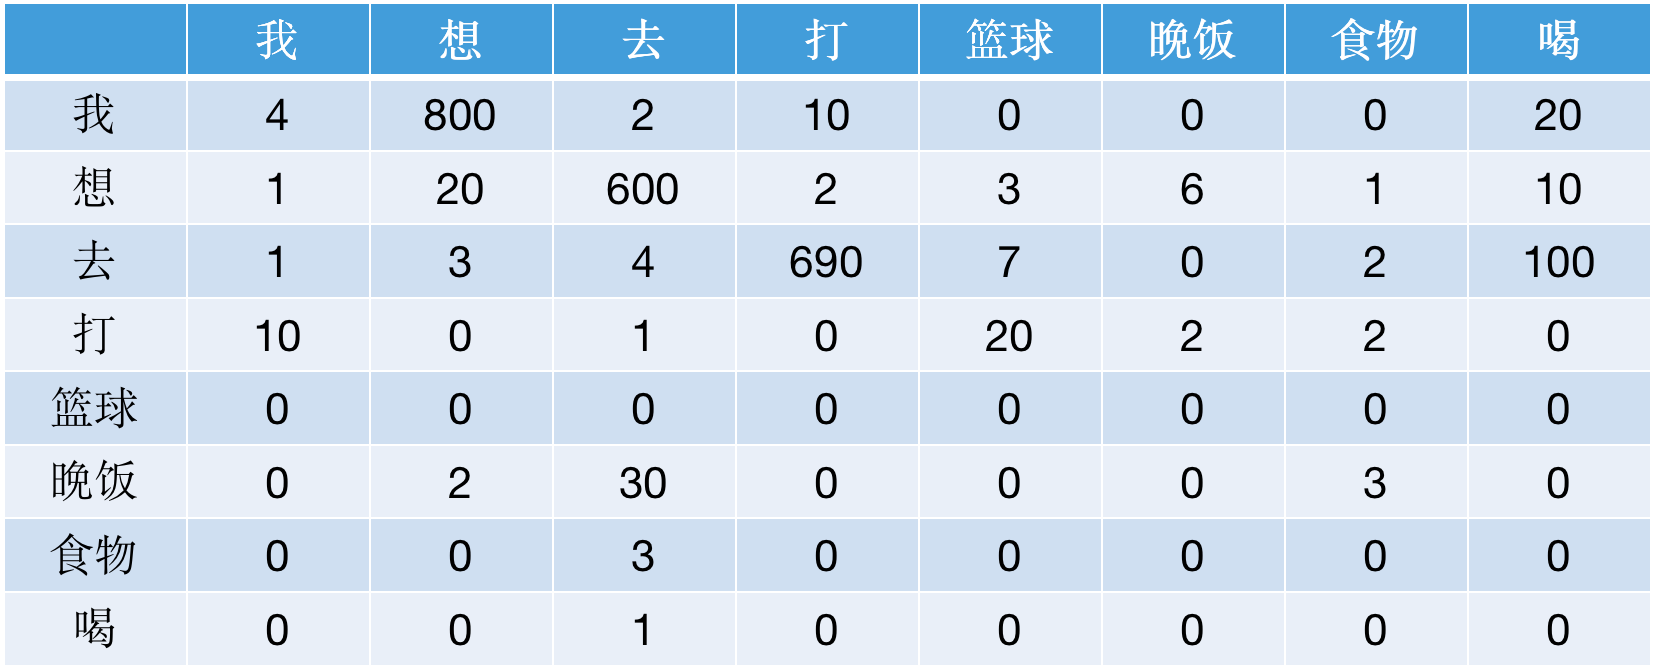

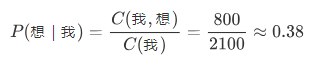

N-gram 的优点是**简单、可解释、容易用最大似然估计**；缺点也很明显：

1. N 增大后参数量快速增长，数据需求大。
2. 只看有限窗口，难以利用长距离依赖。
3. 训练语料中未出现的组合会产生零概率，存在数据稀疏和未登录词问题。
4. 词与词之间主要靠计数关联，泛化能力弱，无法充分理解语义。


### 2.3 神经网络语言模型

神经网络语言模型用词向量代替离散计数。典型流程是：

1. 将上下文词映射为 embedding。
2. 拼接或组合上下文向量。
3. 经过线性层或非线性层（如 `tanh`）。
4. 用 `softmax` 输出词表上每个候选词的概率。

相比 N-gram，词向量可以表达相似性，因此模型具有更好的泛化能力；但早期神经语言模型仍受固定上下文长度限制，长序列建模和梯度传播效果有限。


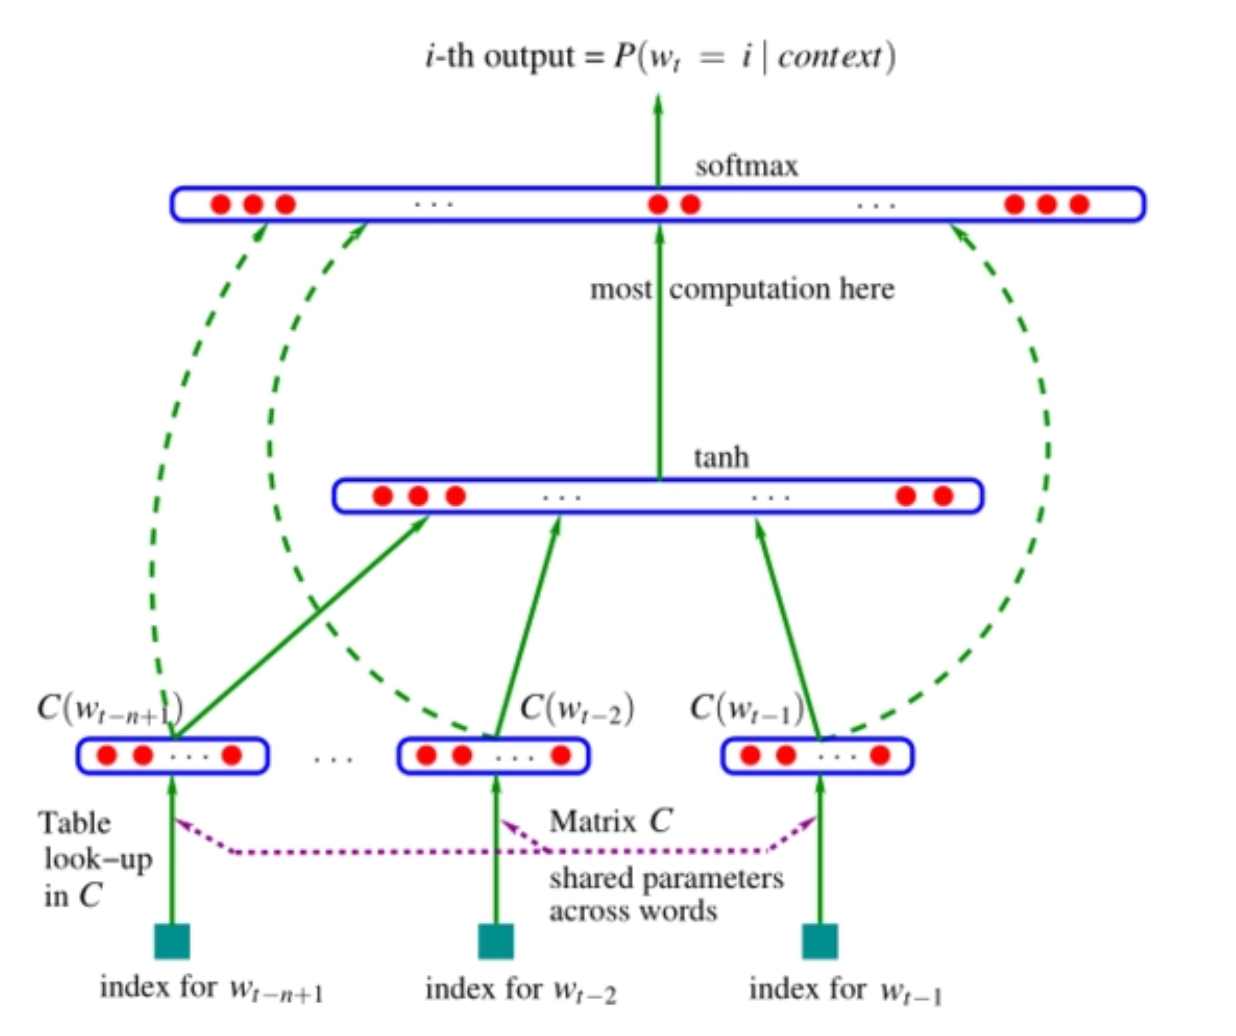

### 2.4 基于 Transformer 的预训练语言模型

Transformer 通过自注意力机制处理序列中的不同位置，能够在更大范围内建模上下文关系。课程强调的范式是：

1. 在大规模通用语料上进行 **Pre-training**，学习语言规律和通用表示。
2. 针对具体任务进行 **Fine-tuning** 或任务适配。

BERT、GPT 等模型都源于 Transformer，但它们使用的训练目标和注意力方向不同。预训练模型的优点是特征更丰富、迁移性能更好；代价是训练计算量更大，模型内部决策也更难解释。


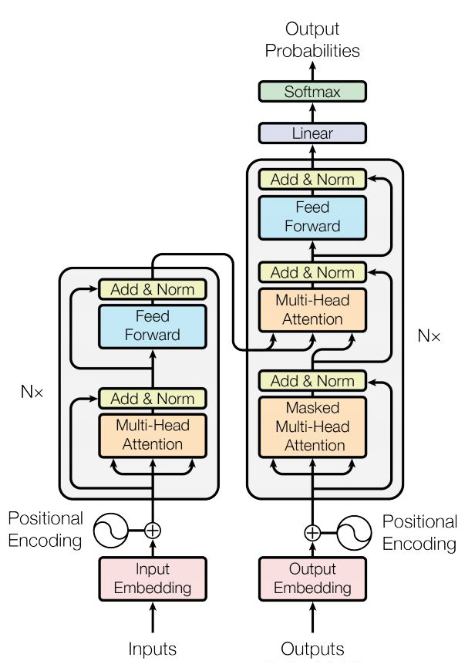

### 2.5 大语言模型的能力与边界

LLM 通常基于 Transformer，通过海量数据和大参数规模学习“根据上文生成下文”的能力。它可以完成：

- 文本生成、摘要、改写和翻译；
- 问答、对话和信息抽取；
- 代码生成，以及与工具、插件配合完成任务。

课程同时列出了几个边界：训练和推理需要大量算力，训练周期长；数据可能带来偏见和有害内容；模型可能生成看似合理但不真实的答案。因此后续训练过程需要关注数据质量、任务目标和安全约束。


## 三、大模型常用评估指标

分类任务常见 `Accuracy`、`Precision`、`Recall` 和 `F1`。生成任务还需要关注生成文本与参考文本之间的重合程度和概率质量。

### 3.1 BLEU：偏重精确率的翻译评价

BLEU 主要用于机器翻译质量评估，取值范围通常为 `[0, 1]`，越大表示生成文本与参考文本的 N-gram 匹配越好。基本流程是：

1. 分别拆分候选文本和参考文本的 1-gram、2-gram、3-gram、4-gram。
2. 统计候选文本中与参考文本匹配的 N-gram 数量。
3. 用匹配数量除以候选文本对应 N-gram 的总数，再按不同阶数加权组合。

为避免模型重复生成同一短语导致分数虚高，BLEU 会使用截断计数：

\[
count_k=\min(c_k,s_k)
\]

其中 `cₖ` 是候选文本中的计数，`sₖ` 是参考文本中的最大计数。


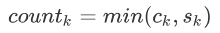

下面是课件中的 NLTK 示例。它使用不同权重分别计算 1 到 4-gram 的 BLEU：

```python
# 第一步安装 nltk：pip install nltk
from nltk.translate.bleu_score import sentence_bleu

def cumulative_bleu(reference, candidate):
    bleu_1_gram = sentence_bleu(reference, candidate, weights=(1, 0, 0, 0))
    bleu_2_gram = sentence_bleu(reference, candidate, weights=(0.5, 0.5, 0, 0))
    bleu_3_gram = sentence_bleu(reference, candidate, weights=(0.33, 0.33, 0.33, 0))
    bleu_4_gram = sentence_bleu(reference, candidate, weights=(0.25, 0.25, 0.25, 0.25))
    return bleu_1_gram, bleu_2_gram, bleu_3_gram, bleu_4_gram

candidate_text = ["This", "is", "some", "generated", "text"]
reference_texts = [["This", "is", "a", "reference", "text"]]
c_bleu = cumulative_bleu(reference_texts, candidate_text)
print("The Bleu score is:", c_bleu)
```


### 3.2 ROUGE：偏重召回率的生成评价

ROUGE 同样比较生成结果和参考结果的重合程度，但更关注参考文本中的信息被生成文本覆盖了多少，属于召回率视角。常见变体包括：

- `ROUGE-N`：比较 N-gram 的召回率；
- `ROUGE-L`：基于最长公共子序列；
- `ROUGE-W`：对连续匹配加权；
- `ROUGE-S`：比较 skip-bigram。

因此可以粗略理解为：**BLEU 更看重候选文本写得准不准，ROUGE 更看重参考信息覆盖得全不全。**


```python
# 第一步安装 rouge：pip install rouge
from rouge import Rouge

generated_text = "This is some generated text."
reference_texts = ["This is another generated reference text."]

rouge = Rouge()
scores = rouge.get_scores(generated_text, reference_texts[0])
print(f"scores-->{scores}")
print("ROUGE-1 precision:", scores[0]["rouge-1"]["p"])
print("ROUGE-1 recall:", scores[0]["rouge-1"]["r"])
print("ROUGE-1 F1 score:", scores[0]["rouge-1"]["f"])
```


### 3.3 困惑度 PPL：衡量概率模型的预测能力

困惑度（Perplexity，PPL）用于度量概率模型预测样本的好坏。对同一数据集来说，PPL 越低，说明模型给真实序列分配的概率越高，预测能力越好。

对于长度为 `N` 的序列：

\[
PP(W)=P(w_1,w_2,\ldots,w_N)^{-1/N}
\]

等价地，也可以使用对数形式：

\[
PP(S)=2^{-rac{1}{N}\sum_{i=1}^{N}\log P(w_i)}
\]


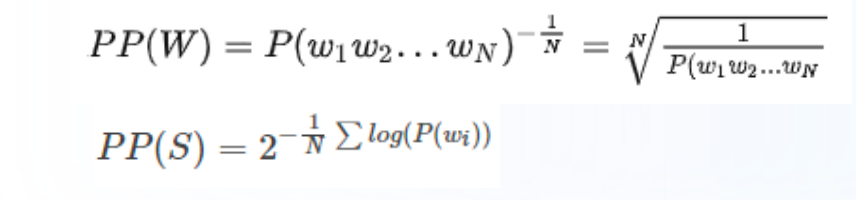

课件中的简单 unigram 计算示例：

```python
import math

sentences = [
    ['I', 'have', 'a', 'pen'],
    ['He', 'has', 'a', 'book'],
    ['She', 'has', 'a', 'cat']
]

unigram = {
    'I': 1/12, 'have': 1/12, 'a': 3/12, 'pen': 1/12,
    'He': 1/12, 'has': 2/12, 'book': 1/12,
    'She': 1/12, 'cat': 1/12
}

perplexity = 0
for sentence in sentences:
    sentence_prob = 1
    for word in sentence:
        sentence_prob *= unigram[word]
    temp = -math.log(sentence_prob, 2) / len(sentence)
    perplexity += 2 ** temp

perplexity = perplexity / len(sentences)
print('困惑度为：', perplexity)
```

课程示例输出约为 `8.15`。这个例子是为了说明计算过程，真实 LLM 通常在 token 级别、按更复杂的条件概率计算 PPL。


## 四、LLM 的三类主流架构

Transformer 通常由多层注意力和前馈网络组成。按照 Transformer 中使用的模块不同，LLM 可以分为：

| 类型 | 代表模型 | 注意力方向 | 典型任务 |
| --- | --- | --- | --- |
| Encoder-only | BERT | 双向理解上下文 | 分类、匹配、抽取、编码 |
| Decoder-only | GPT | 从左到右生成 | 对话、续写、代码生成 |
| Encoder-Decoder | T5 | 编码输入后生成输出 | 统一的 text-to-text 任务 |


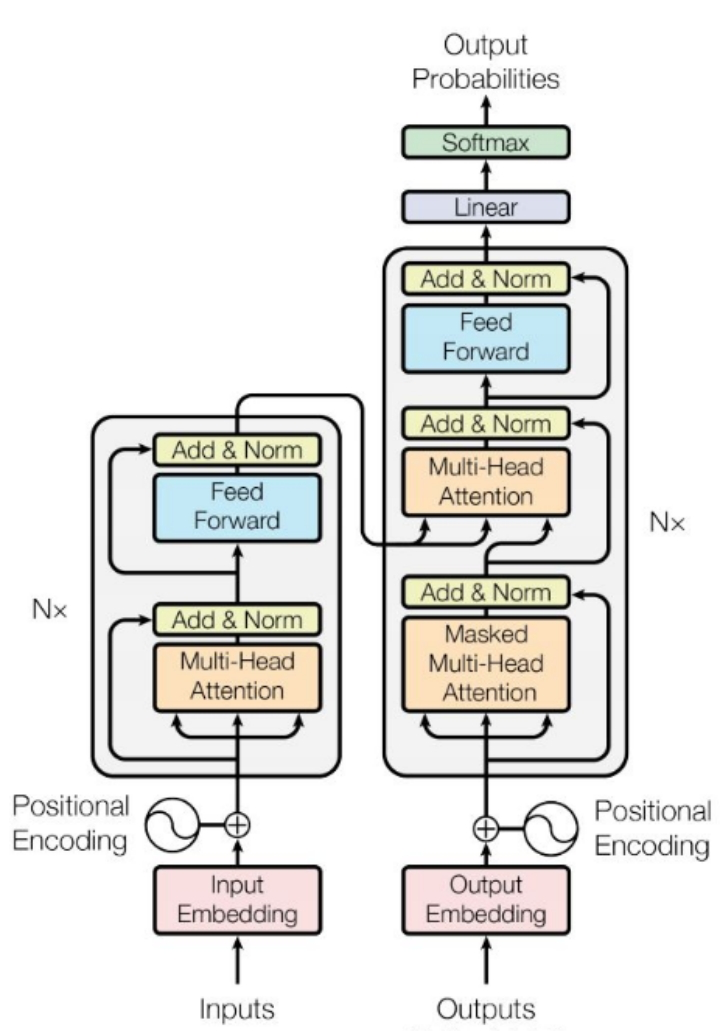

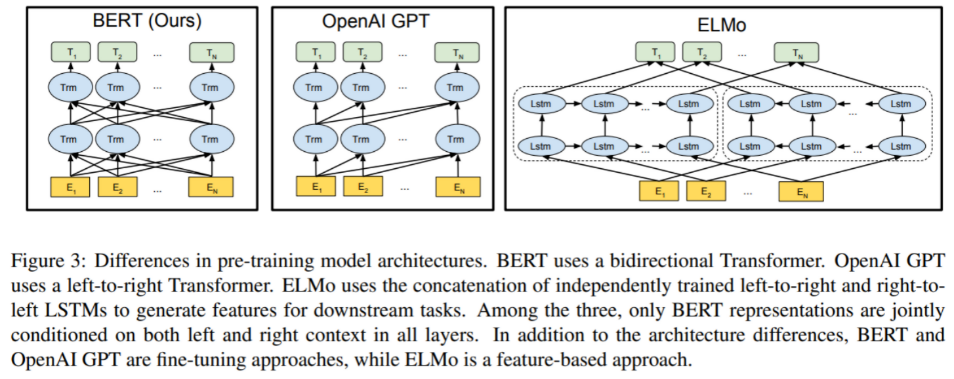

### 4.1 自编码模型 AE：以 BERT 为代表

BERT（Bidirectional Encoder Representations from Transformers）是 Google 在 2018 年提出的 Encoder-only 模型。它通过遮盖输入中的部分 token，再利用左右两侧上下文恢复被遮盖内容，学习双向语言表示。

#### 训练目标

**MLM（Masked Language Model）**：随机选择约 15% 的 token：

- 其中 80% 替换为 `[MASK]`；
- 10% 替换为随机 token；
- 10% 保持原样。

这样可以避免模型只记住 `[MASK]` 这个特殊标记。

**NSP（Next Sentence Prediction）**：构造句子对，其中 50% 是真实的前后句，50% 是随机句子，用于判断两句是否相邻。

#### 输入表示

BERT 的输入向量由三部分相加：

\[
Embedding=Token\ Embedding+Segment\ Embedding+Position\ Embedding
\]

`[CLS]` 位置的向量可以用于分类，`[SEP]` 用于分隔句子。


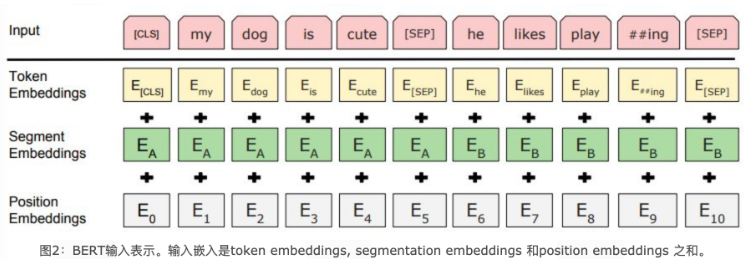

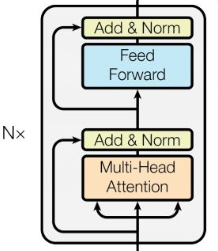

#### BERT 的规模与特点

课程课件给出的 BERT-base 配置为：12 层 Transformer、隐藏维度 768、12 个注意力头、约 110M 参数。预训练语料包括 BooksCorpus（约 800M 字）和 Wikipedia（约 2.5B 字）。

优点是双向上下文建模能力强，适合理解类任务；局限是预训练中的 `[MASK]` 与下游真实输入存在差异，而且 Encoder-only 结构本身不擅长连续文本生成。


### 4.2 自回归模型 AR：以 GPT 为代表

GPT（Generative Pre-trained Transformer）是 OpenAI 提出的 Decoder-only 模型，按照从左到右的顺序预测下一个 token。给定前缀 `w₁,...,wₜ₋₁`，模型估计：

\[
P(w_t|w_1,\ldots,w_{t-1})
\]

GPT 的 Decoder 保留 masked self-attention 和前馈网络，去掉了 Encoder-Decoder attention；因果 mask 保证当前位置不能看到未来 token。


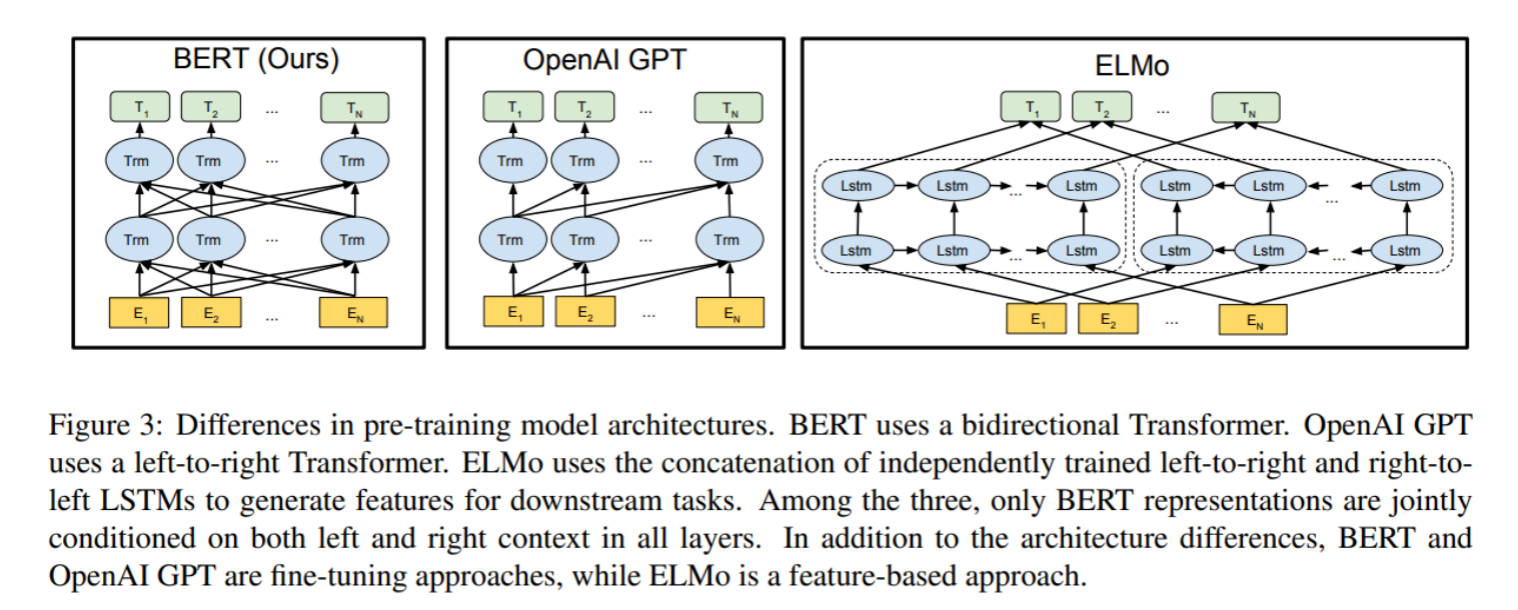

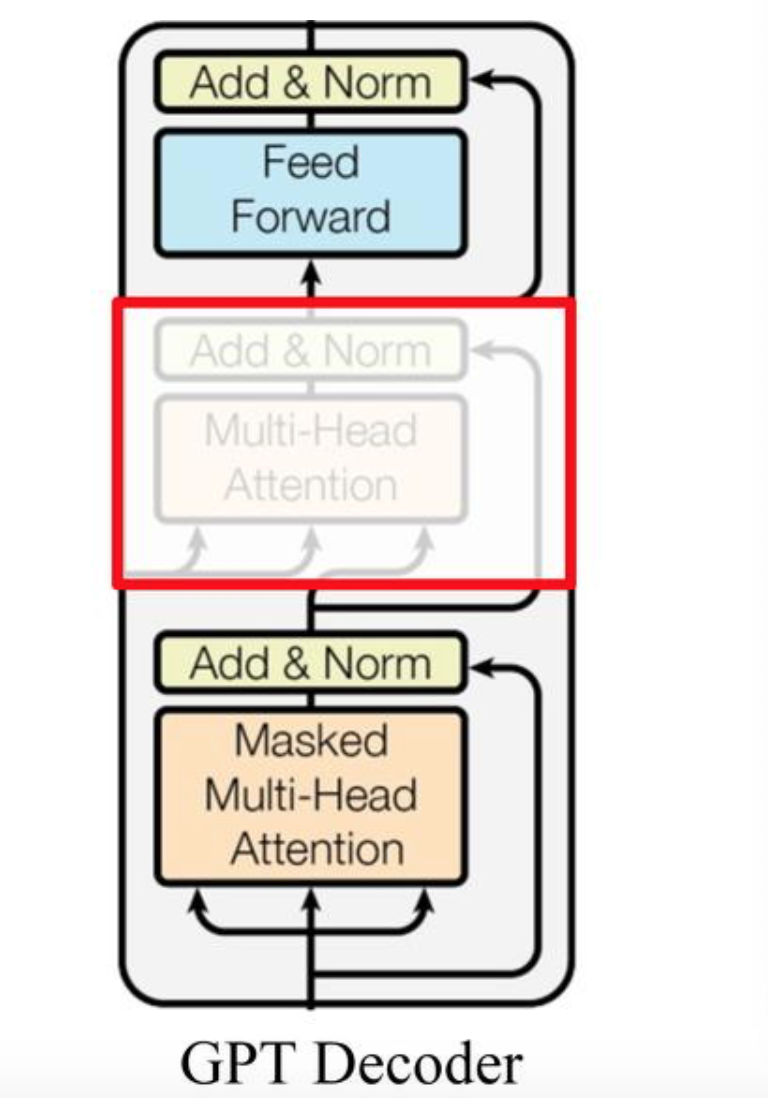

#### GPT 的训练流程

1. **无监督预训练**：在大量文本上使用语言模型目标，预测下一个词。
2. **监督微调**：使用带标签的任务数据，让模型适应具体任务。
3. **下游使用**：可以直接生成文本，也可以结合提示完成多种任务。

GPT-1 的课件配置为 12 个 Transformer block、隐藏维度 768、12 个注意力头、约 117M 参数，预训练语料为 BooksCorpus（约 5GB、7400 万句以上）。

GPT 的优势是天然适合生成，训练时可以利用因果语言模型进行高效并行；局限是单向上下文，在需要双向理解的任务上不如 Encoder-only 模型直接，早期模型还依赖针对任务的监督微调。


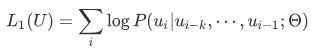

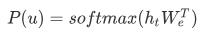

### 4.3 Encoder-Decoder 模型：以 T5 为代表

T5（Text-to-Text Transfer Transformer）把各种 NLP 任务统一改写成文本到文本：

- 分类：输入问题，输出类别文本；
- 翻译：输入一种语言，输出另一种语言；
- 摘要：输入长文，输出摘要。

因此不同任务可以共享同一套模型、损失函数和解码方式。

课件介绍的 T5 改动包括：简化 LayerNorm、使用相对位置偏置、使用经过过滤的 C4 Common Crawl 数据集，并结合因果语言模型、MLM 和多任务监督预训练。示例配置为 24 层、隐藏维度 768、12 个注意力头、约 220M 参数。


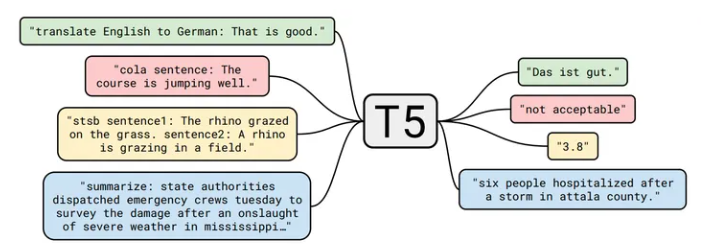

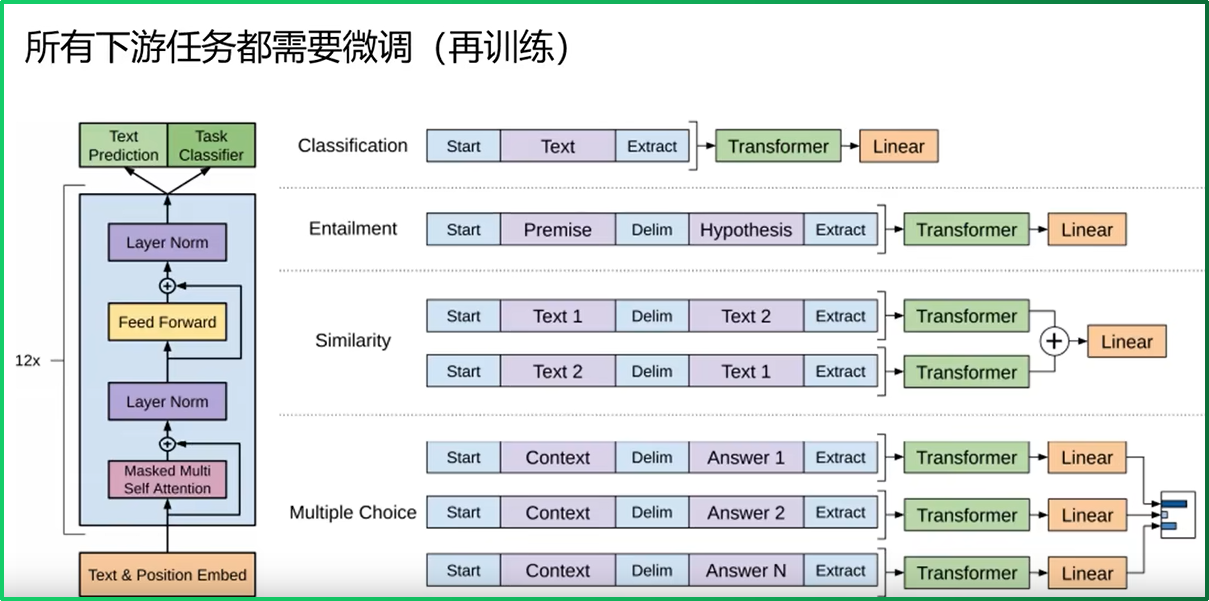

T5 的优点是统一了多种 NLP 任务的输入输出形式，模型复用性强；代价是训练和推理计算量较大，模型内部过程也不容易解释。


### 4.4 为什么 Decoder-only 成为主流

课程最后将主流架构归纳为 Decoder-only，原因可以从三方面理解：

1. **生成目标统一**：文本、代码和对话都可以转化为“根据前文预测后文”。
2. **训练效率高**：训练阶段可以对整段序列并行计算，因果 mask 只约束信息可见性。
3. **扩展简单**：增加数据和参数后，模型可以通过提示适配更多任务，不必为每个任务设计单独输出头。

Encoder-only 更擅长双向理解，Encoder-Decoder 适合明确的输入到输出转换；但在通用生成、规模扩展和工程统一性方面，Decoder-only 更符合当前大模型的发展路线。


## 五、本章小结

- 语言模型的核心是估计文本概率，现代训练通常落到下一个 token 预测。
- N-gram 简单可解释，但受限于短上下文、数据稀疏和弱泛化。
- 神经网络和 Transformer 通过向量表示、自注意力和预训练显著提升了建模能力。
- BLEU 偏重精确率，ROUGE 偏重召回率，PPL 越低通常表示概率预测越好。
- BERT 是双向 Encoder-only 模型，GPT 是单向自回归 Decoder-only 模型，T5 将任务统一为 text-to-text。
- Decoder-only 由于生成目标统一、训练扩展方便，成为当前大模型的主流架构。
